<a href="https://colab.research.google.com/github/jauzakrito/Smart_Science_and_Technology_for_Innovation_Jauza/blob/main/Smart_Science_and_Technology_for_Innovation_Jauza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimating Solar AC Power from Irradiation and Temperature

## Introduction

Solar power output varies throughout the day as environmental conditions
change. Estimating the expected output from local sensor measurements can
help plant operators identify periods when the measured output differs
from what those conditions would suggest.

This study asks whether ambient and module temperatures improve the
estimation of AC power beyond what can be achieved using solar irradiation
alone. Two linear regression models are evaluated on the same seven-day
test period at Plant 1.

## Dataset

The Solar Power Generation Data dataset contains generation and weather
measurements from two solar power plants in India over 34 days. This study
uses Plant 1. Its generation file records AC power separately for each
inverter, while its weather file records irradiation, ambient temperature,
and module temperature at the plant level.

Source: [Solar Power Generation Data, Kaggle](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data)

In [ ]:
from io import BytesIO
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import requests
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Read both Plant 1 files directly from the original Kaggle archive.
url = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "anikannal/solar-power-generation-data"
)
response = requests.get(url, timeout=120)
response.raise_for_status()

with ZipFile(BytesIO(response.content)) as archive:
    with archive.open("Plant_1_Generation_Data.csv") as file:
        generation = pd.read_csv(file)
    with archive.open("Plant_1_Weather_Sensor_Data.csv") as file:
        weather = pd.read_csv(file)

print(f"Generation records: {len(generation):,}")
print(f"Weather records: {len(weather):,}")

print("\nGeneration data")
display(generation.head(3))

print("\nWeather sensor data")
display(weather.head(3))

Generation records: 68,778
Weather records: 3,182

Generation data


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0



Weather sensor data


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0


## Methods

The target variable is total plant AC power at each 15-minute timestamp.
Inverter readings are summed only when all 22 inverters have a recorded
power value. This prevents a missing inverter reading from appearing as
a drop in plant output. A recorded power value of zero is retained.

Two linear regression models are compared. Model A uses irradiation alone.
Model B adds ambient temperature and module temperature. Linear regression
provides a simple baseline for measuring how much the additional variables
change estimation accuracy.

The models are trained on the earlier dates and evaluated on the final
seven calendar days. Both use the same training and test observations.
Performance is measured using mean absolute error (MAE), expressed in
the same units as AC power. MAE is calculated for the full test period
and separately for observations with positive irradiation.

In [ ]:
# Parse the date format used in each original CSV.
generation["DATE_TIME"] = pd.to_datetime(
    generation["DATE_TIME"], format="%d-%m-%Y %H:%M"
)
weather["DATE_TIME"] = pd.to_datetime(
    weather["DATE_TIME"], format="%Y-%m-%d %H:%M:%S"
)

keys = ["PLANT_ID", "DATE_TIME"]
features = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]

# Verify that each inverter has at most one reading per timestamp.
assert not generation.duplicated(keys + ["SOURCE_KEY"]).any(), (
    "Duplicate inverter readings found."
)
assert not weather.duplicated(keys).any(), "Duplicate weather readings found."

# Calculate plant output only when all inverters have a power reading.
n_inverters = generation["SOURCE_KEY"].nunique()

plant_power = (
    generation.dropna(subset=["SOURCE_KEY", "AC_POWER"])
    .groupby(keys, as_index=False)
    .agg(
        inverter_count=("SOURCE_KEY", "nunique"),
        AC_POWER=("AC_POWER", "sum"),
    )
)

complete = plant_power.loc[plant_power["inverter_count"] == n_inverters]

data = (
    complete.merge(weather[keys + features], on=keys, validate="one_to_one")
    .dropna(subset=features)
    .sort_values("DATE_TIME")
    .reset_index(drop=True)
)

# Reserve the final seven calendar days for testing.
test_start = data["DATE_TIME"].max().normalize() - pd.Timedelta(days=6)
train = data.loc[data["DATE_TIME"] < test_start].copy()
test = data.loc[data["DATE_TIME"] >= test_start].copy()

print(f"Number of inverters: {n_inverters}")
print(f"Matched observations: {len(data):,}")

for name, subset in [("Training", train), ("Testing", test)]:
    dates = subset["DATE_TIME"].dt.date
    print(f"{name}: {dates.min()} to {dates.max()} | {len(subset):,} observations")

display(data.head())

Number of inverters: 22
Matched observations: 3,057
Training: 2020-05-15 to 2020-06-10 | 2,387 observations
Testing: 2020-06-11 to 2020-06-17 | 670 observations


,PLANT_ID,DATE_TIME,inverter_count,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
0,4135001,2020-05-15 01:00:00,22,0.0,0.0,24.621525,22.165423
1,4135001,2020-05-15 01:45:00,22,0.0,0.0,24.873022,23.160919
2,4135001,2020-05-15 04:15:00,22,0.0,0.0,24.351931,21.783643
3,4135001,2020-05-15 04:30:00,22,0.0,0.0,24.062622,21.852525
4,4135001,2020-05-15 04:45:00,22,0.0,0.0,24.013224,22.306315


In [ ]:
# Compare both models using the same training and test observations.
model_features = {
    "Model A": ["IRRADIATION"],
    "Model B": ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"],
}

positive_irradiation = test["IRRADIATION"] > 0
rows = []

for name, columns in model_features.items():
    model = LinearRegression()
    model.fit(train[columns], train["AC_POWER"])
    test[name] = model.predict(test[columns])

    rows.append({
        "Model": name,
        "MAE (all observations)": mean_absolute_error(
            test["AC_POWER"], test[name]
        ),
        "MAE (positive irradiation)": mean_absolute_error(
            test.loc[positive_irradiation, "AC_POWER"],
            test.loc[positive_irradiation, name],
        ),
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(2))

,MAE (all observations),MAE (positive irradiation)
Model,,
Model A,496.49,764.89
Model B,495.07,794.39


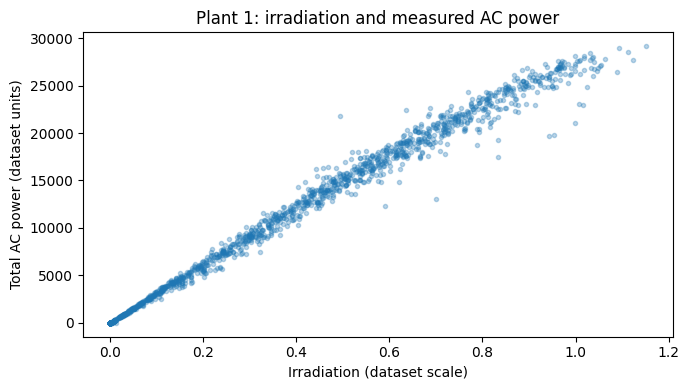

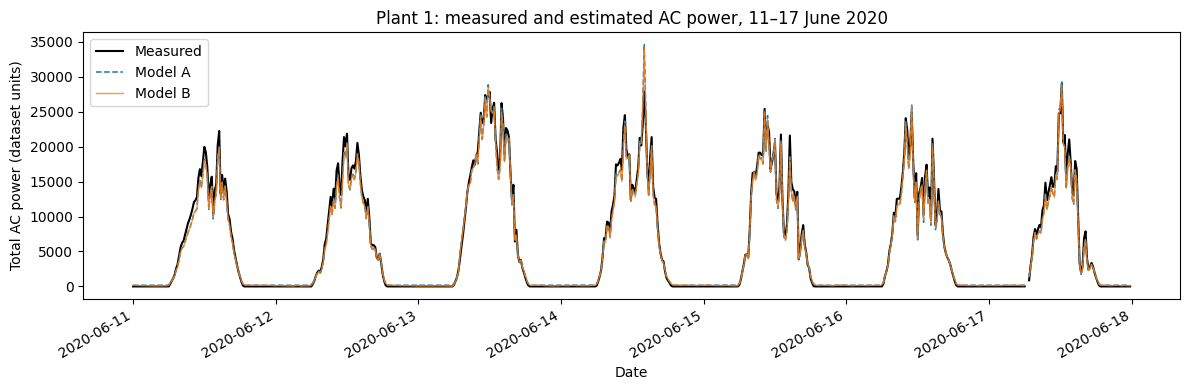

In [ ]:
# Figure 1. Relationship between irradiation and measured AC power.
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(train["IRRADIATION"], train["AC_POWER"], s=9, alpha=0.3)
ax.set(
    title="Plant 1: irradiation and measured AC power",
    xlabel="Irradiation (dataset scale)",
    ylabel="Total AC power (dataset units)",
)
fig.tight_layout()
fig.savefig("figure_1_irradiation_and_power.png", dpi=200)
plt.show()

# Figure 2. Measured and estimated output during the test period.
# Missing 15-minute observations appear as gaps in the lines.
plot_data = (
    test.set_index("DATE_TIME")[["AC_POWER", "Model A", "Model B"]]
    .asfreq("15min")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(plot_data.index, plot_data["AC_POWER"],
        color="black", linewidth=1.5, label="Measured")
ax.plot(plot_data.index, plot_data["Model A"],
        linestyle="--", linewidth=1.1, label="Model A")
ax.plot(plot_data.index, plot_data["Model B"],
        linewidth=1, alpha=0.8, label="Model B")
ax.set(
    title="Plant 1: measured and estimated AC power, 11–17 June 2020",
    xlabel="Date",
    ylabel="Total AC power (dataset units)",
)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("figure_2_test_predictions.png", dpi=200)
plt.show()

## Extension: Does the Effect of Module Temperature Depend on Irradiation?

Model B assumes that a one-degree change in module temperature produces
the same change in estimated AC power at every irradiation level. Model C
relaxes this assumption by adding one interaction term:

interaction = irradiation × (module temperature − 25 °C).

Model C retains all three predictors from Model B. The reference
temperature of 25 °C makes the equation easier to interpret. It does
not affect the fitted predictions because irradiation is also included
as a separate predictor.

To examine whether the improvement is consistent over time, we compare
Models A, B, and C across three consecutive seven-day periods. For each
period, the models are fitted using only observations from earlier dates.
We report the mean absolute error (MAE) for all observations and for
observations with positive irradiation.

In [ ]:
# Build the interaction feature using the matched Plant 1 observations.
analysis = data.copy()
analysis["IRRADIATION_X_MODULE_TEMP"] = (
    analysis["IRRADIATION"] * (analysis["MODULE_TEMPERATURE"] - 25)
)

model_inputs = {
    "Model A": ["IRRADIATION"],
    "Model B": ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"],
    "Model C": [
        "IRRADIATION",
        "AMBIENT_TEMPERATURE",
        "MODULE_TEMPERATURE",
        "IRRADIATION_X_MODULE_TEMP",
    ],
}

week_starts = pd.to_datetime(["2020-05-28", "2020-06-04", "2020-06-11"])
score_rows = []
coefficient_rows = []

for start in week_starts:
    end = start + pd.Timedelta(days=7)
    training = analysis.loc[analysis["DATE_TIME"] < start]
    testing = analysis.loc[
        (analysis["DATE_TIME"] >= start) & (analysis["DATE_TIME"] < end)
    ]
    positive = testing["IRRADIATION"] > 0
    week = f"{start:%d %b} – {end - pd.Timedelta(days=1):%d %b}"

    for name, columns in model_inputs.items():
        model = LinearRegression()
        model.fit(training[columns], training["AC_POWER"])
        predictions = model.predict(testing[columns])

        score_rows.append({
            "Evaluation week": week,
            "Model": name,
            "MAE (all observations)": mean_absolute_error(
                testing["AC_POWER"], predictions
            ),
            "MAE (positive irradiation)": mean_absolute_error(
                testing.loc[positive, "AC_POWER"], predictions[positive]
            ),
        })

        if name == "Model C":
            coefficients = pd.Series(model.coef_, index=columns)
            coefficient_rows.append({
                "Evaluation week": week,
                "Module temperature coefficient": coefficients["MODULE_TEMPERATURE"],
                "Interaction coefficient": coefficients["IRRADIATION_X_MODULE_TEMP"],
            })

scores = pd.DataFrame(score_rows)

for metric in ["MAE (all observations)", "MAE (positive irradiation)"]:
    print(metric)
    table = scores.pivot(index="Evaluation week", columns="Model", values=metric)
    display(table.reindex(scores["Evaluation week"].unique()).round(2))

print("Model C coefficients fitted using observations before each evaluation week")
display(pd.DataFrame(coefficient_rows).set_index("Evaluation week").round(2))

MAE (all observations)


Model,Model A,Model B,Model C
Evaluation week,,,
28 May – 03 Jun,474.68,456.02,352.21
04 Jun – 10 Jun,506.18,469.02,419.17
11 Jun – 17 Jun,496.49,495.07,289.16


MAE (positive irradiation)


Model,Model A,Model B,Model C
Evaluation week,,,
28 May – 03 Jun,715.90,732.88,550.87
04 Jun – 10 Jun,778.81,771.74,680.29
11 Jun – 17 Jun,764.89,794.39,483.05


Model C coefficients fitted using observations before each evaluation week


,Module temperature coefficient,Interaction coefficient
Evaluation week,,
28 May – 03 Jun,58.53,-116.48
04 Jun – 10 Jun,74.83,-135.37
11 Jun – 17 Jun,74.33,-144.11


## Comparing Linear Regression and Random Forest Regression

This analysis asks two questions. First, does the relationship between
module temperature and estimated AC power depend on irradiation? Second,
can a random forest estimate power more accurately using the same sensor
measurements?

| Model | Algorithm | Predictors |
|---|---|---|
| A | Linear regression | Irradiation |
| B | Linear regression | Irradiation, ambient temperature, module temperature |
| C | Linear regression | Model B predictors plus irradiation × (module temperature − 25 °C) |
| D | Random forest regression | Irradiation, ambient temperature, module temperature |

Comparing A with B tests whether adding temperature improves a linear
model. Comparing B with C tests the contribution of an explicit interaction.
Comparing B with D tests the choice of algorithm while keeping the inputs
identical. The random forest can learn nonlinear relationships and
interactions through its decision trees.

Each model is evaluated over three consecutive seven-day periods. Before
each period, the model is fitted using only observations from earlier dates.
For each week, we calculate mean absolute error (MAE) over all test
observations and separately over observations with positive irradiation.
The second measure shows how accurately each model estimates output when
the irradiation sensor records sunlight.

In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Start from the matched Plant 1 observations created in Cell 4.
analysis = data.sort_values("DATE_TIME").copy()
interaction = "IRRADIATION_X_MODULE_TEMP"
analysis[interaction] = (
    analysis["IRRADIATION"] * (analysis["MODULE_TEMPERATURE"] - 25)
)

sensor_features = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]

models = {
    "A": (LinearRegression(), ["IRRADIATION"]),
    "B": (LinearRegression(), sensor_features),
    "C": (LinearRegression(), sensor_features + [interaction]),
    "D": (
        RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1,
        ),
        sensor_features,
    ),
}

week_starts = pd.to_datetime(["2020-05-28", "2020-06-04", "2020-06-11"])
score_rows = []
interaction_rows = []

for start in week_starts:
    end = start + pd.Timedelta(days=7)
    train_week = analysis.loc[analysis["DATE_TIME"] < start]
    test_week = analysis.loc[
        (analysis["DATE_TIME"] >= start) & (analysis["DATE_TIME"] < end)
    ]
    positive = test_week["IRRADIATION"] > 0
    week_label = f"{start:%d %b} – {end - pd.Timedelta(days=1):%d %b}"

    for name, (model, columns) in models.items():
        model.fit(train_week[columns], train_week["AC_POWER"])
        predictions = model.predict(test_week[columns])

        score_rows.append({
            "Week": week_label,
            "Model": name,
            "MAE (all observations)": mean_absolute_error(
                test_week["AC_POWER"], predictions
            ),
            "MAE (positive irradiation)": mean_absolute_error(
                test_week.loc[positive, "AC_POWER"], predictions[positive]
            ),
        })

        if name == "C":
            coefficients = pd.Series(model.coef_, index=columns)
            interaction_rows.append({
                "Week": week_label,
                "Interaction coefficient": coefficients[interaction],
            })

scores = pd.DataFrame(score_rows)
week_order = scores["Week"].drop_duplicates()

for metric in ["MAE (all observations)", "MAE (positive irradiation)"]:
    print(metric)
    table = scores.pivot(index="Week", columns="Model", values=metric)
    display(table.reindex(week_order).round(2))

print("Model C: fitted irradiation–temperature interaction")
display(pd.DataFrame(interaction_rows).set_index("Week").round(2))

MAE (all observations)


Model,A,B,C,D
Week,,,,
28 May – 03 Jun,474.68,456.02,352.21,343.17
04 Jun – 10 Jun,506.18,469.02,419.17,382.43
11 Jun – 17 Jun,496.49,495.07,289.16,277.24


MAE (positive irradiation)


Model,A,B,C,D
Week,,,,
28 May – 03 Jun,715.90,732.88,550.87,595.78
04 Jun – 10 Jun,778.81,771.74,680.29,689.41
11 Jun – 17 Jun,764.89,794.39,483.05,504.76


Model C: fitted irradiation–temperature interaction


,Interaction coefficient
Week,
28 May – 03 Jun,-116.48
04 Jun – 10 Jun,-135.37
11 Jun – 17 Jun,-144.11


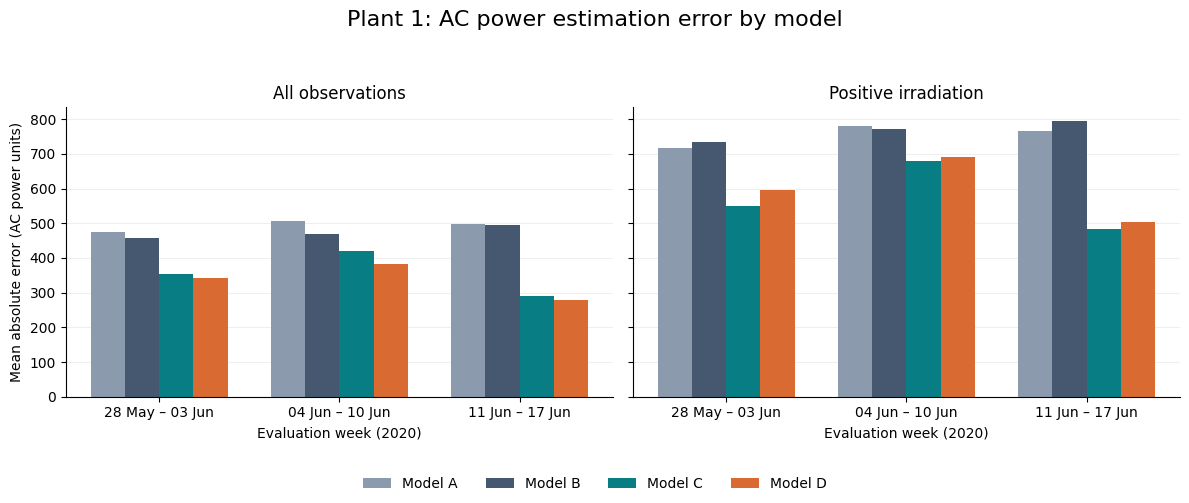

In [7]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["MAE (all observations)", "MAE (positive irradiation)"]
titles = ["All observations", "Positive irradiation"]
colors = ["#8B9AAC", "#465870", "#087E84", "#D86A32"]

weeks = scores["Week"].drop_duplicates().tolist()
x = np.arange(len(weeks))
width = 0.19

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, metric, title in zip(axes, metrics, titles):
    table = scores.pivot(index="Week", columns="Model", values=metric).loc[weeks]

    for i, model in enumerate(["A", "B", "C", "D"]):
        ax.bar(
            x + (i - 1.5) * width,
            table[model],
            width,
            label=f"Model {model}",
            color=colors[i],
        )

    ax.set_title(title)
    ax.set_xticks(x, weeks)
    ax.set_xlabel("Evaluation week (2020)")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Mean absolute error (AC power units)")
fig.suptitle("Plant 1: AC power estimation error by model", fontsize=16)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=[0, 0.09, 1, 0.93])

fig.savefig("plant1_model_errors.png", dpi=200, bbox_inches="tight")
plt.show()

Mean absolute error of four models across three evaluation weeks at Plant 1. Model A uses irradiation alone. Model B adds ambient and module temperatures, and Model C adds an irradiation–module temperature interaction. Model D uses a random forest with the same inputs as Model B. Lower bars indicate more accurate estimates. Model D had the lowest overall error in each week, while Model C had the lowest error when irradiation was positive.

## Results and Discussion

The analysis retained 3,057 timestamps with complete inverter and weather
measurements. In the final evaluation week (11–17 June), 2,387 earlier
observations were available for training and 670 observations for testing.

### Does temperature improve the linear model?

During the final week, adding ambient and module temperatures to the
irradiation-only model changed the overall MAE from 496.49 (Model A) to
495.07 (Model B). During periods with positive irradiation, the error
increased from 764.89 to 794.39.

Allowing the module-temperature slope to vary with irradiation produced
a larger improvement. Model C reduced the final-week positive-irradiation
MAE from 794.39 to 483.05, a reduction of 39.2% relative to Model B.
The fitted interaction coefficient was negative in all three training
periods. This describes an association in the Plant 1 measurements.

### Does the random forest improve estimation?

Models B and D used identical sensor inputs. The random forest achieved
lower MAE than Model B in every evaluation week, both overall and during
positive irradiation. This shows that the choice of algorithm mattered
even when the available measurements were held constant.

The comparison with Model C depended on the evaluation condition. Model D
had the lowest overall MAE among all four models in every week. Model C
had the lowest MAE during positive irradiation in every week. In the final
week, for example, Model D had an overall MAE of 277.24 compared with
289.16 for Model C. During positive irradiation, Model C achieved 483.05
compared with 504.76 for Model D.

### Conclusion

For Plant 1, the random forest gave the most accurate estimates when
performance was averaged across all recorded conditions. For estimating
output specifically during positive irradiation, linear regression with
an explicit irradiation–temperature interaction performed best. Reporting
both metrics matters because the overall MAE alone would select a different
model for this second objective.

These comparisons are exploratory. They cover three weeks at one plant,
and the interaction was investigated after the initial results had been
reviewed. All four models use concurrent sensor readings to estimate AC
power at the same timestamp.